In [1]:
# Step 1: Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

print("Libraries imported successfully")

Libraries imported successfully


In [2]:
# Dataset from the PPT
data = {
    "StudyHours": [2, 4, 6, 8, 10],
    "Attendance": [60, 70, 80, 90, 100],
    "PreviousMarks": [55, 65, 75, 85, 95],
    "AssignmentMarks": [50, 60, 70, 80, 90]
}

df = pd.DataFrame(data)

print("Original Data:")
display(df)

Original Data:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,2,60,55,50
1,4,70,65,60
2,6,80,75,70
3,8,90,85,80
4,10,100,95,90


In [3]:
# Apply Min-Max Normalization
minmax_scaler = MinMaxScaler()
normalized_data = minmax_scaler.fit_transform(df)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=df.columns
)

print("Normalized Data:")
display(normalized_df.round(2))

Normalized Data:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,0.00,0.00,0.00,0.00
1,0.25,0.25,0.25,0.25
2,0.50,0.50,0.50,0.50
3,0.75,0.75,0.75,0.75
4,1.00,1.00,1.00,1.00


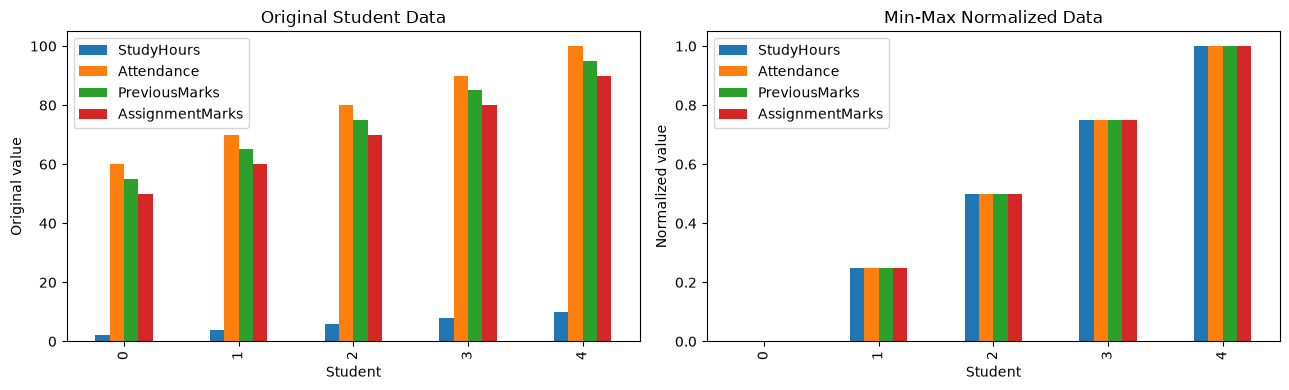

In [4]:
# Plot original and normalized values
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

df.plot(kind="bar", ax=axes[0], title="Original Student Data")
normalized_df.plot(kind="bar", ax=axes[1], title="Min-Max Normalized Data")

axes[0].set_xlabel("Student")
axes[1].set_xlabel("Student")
axes[0].set_ylabel("Original value")
axes[1].set_ylabel("Normalized value")
plt.tight_layout()
plt.show()

In [5]:
# Standardize StudyHours as demonstrated in the PPT
study_hours = np.array([2, 4, 6, 8, 10])

mean_value = np.mean(study_hours)
std_value = np.std(study_hours, ddof=0)  # population standard deviation
z_scores = (study_hours - mean_value) / std_value

study_standardized_df = pd.DataFrame({
    "Student": ["S1", "S2", "S3", "S4", "S5"],
    "StudyHours": study_hours,
    "Z-score": z_scores
})

print("Mean:", mean_value)
print("Population standard deviation:", round(std_value, 4))
print("\nStandardization Table:")
display(study_standardized_df.round(3))

Mean: 6.0
Population standard deviation: 2.8284

Standardization Table:


,Student,StudyHours,Z-score
0,S1,2,-1.414
1,S2,4,-0.707
2,S3,6,0.000
3,S4,8,0.707
4,S5,10,1.414


In [6]:
# Standardize all four features using StandardScaler
standard_scaler = StandardScaler()
standardized_data = standard_scaler.fit_transform(df)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=df.columns
)

print("Standardized Data:")
display(standardized_df.round(3))

print("\nColumn means (approximately 0):")
print(standardized_df.mean().round(6))

print("\nColumn standard deviations (population, approximately 1):")
print(standardized_df.std(ddof=0).round(6))

Standardized Data:


,StudyHours,Attendance,PreviousMarks,AssignmentMarks
0,-1.414,-1.414,-1.414,-1.414
1,-0.707,-0.707,-0.707,-0.707
2,0.000,0.000,0.000,0.000
3,0.707,0.707,0.707,0.707
4,1.414,1.414,1.414,1.414



Column means (approximately 0):
StudyHours         0.0
Attendance         0.0
PreviousMarks      0.0
AssignmentMarks    0.0
dtype: float64

Column standard deviations (population, approximately 1):
StudyHours         1.0
Attendance         1.0
PreviousMarks      1.0
AssignmentMarks    1.0
dtype: float64


In [7]:
# PCA sample dataset from the PPT
pca_data = pd.DataFrame({
    "StudyHours": [1, 2, 3, 4],
    "PreviousMarks": [2, 3, 4, 5]
}, index=["S1", "S2", "S3", "S4"])

print("Original PCA Dataset:")
display(pca_data)

Original PCA Dataset:


,StudyHours,PreviousMarks
S1,1,2
S2,2,3
S3,3,4
S4,4,5


In [8]:
# Step 1: Standardize the two features
pca_scaler = StandardScaler()
pca_standardized = pca_scaler.fit_transform(pca_data)

pca_standardized_df = pd.DataFrame(
    pca_standardized,
    columns=pca_data.columns,
    index=pca_data.index
)

print("Standardized PCA Dataset:")
display(pca_standardized_df.round(6))

Standardized PCA Dataset:


,StudyHours,PreviousMarks
S1,-1.341641,-1.341641
S2,-0.447214,-0.447214
S3,0.447214,0.447214
S4,1.341641,1.341641


In [9]:
# Step 2: Calculate covariance matrix
# The PPT divides by n-1 when calculating covariance.
covariance_matrix = np.cov(pca_standardized.T, ddof=1)

covariance_df = pd.DataFrame(
    covariance_matrix,
    index=pca_data.columns,
    columns=pca_data.columns
)

print("Covariance Matrix:")
display(covariance_df.round(6))

Covariance Matrix:


,StudyHours,PreviousMarks
StudyHours,1.333333,1.333333
PreviousMarks,1.333333,1.333333


In [10]:
# Step 3: Calculate eigenvalues and eigenvectors
eigenvalues, eigenvectors = np.linalg.eig(covariance_matrix)

# Sort eigenvalues from largest to smallest
order = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[order]
eigenvectors = eigenvectors[:, order]

print("Eigenvalues:")
print(eigenvalues)

print("\nEigenvectors (columns correspond to principal components):")
print(eigenvectors)

Eigenvalues:
[2.66666667 0.        ]

Eigenvectors (columns correspond to principal components):
[[ 0.70710678 -0.70710678]
 [ 0.70710678  0.70710678]]


In [11]:
# Step 4: Calculate explained variance percentage
explained_variance_ratio = eigenvalues / np.sum(eigenvalues) * 100

explained_df = pd.DataFrame({
    "Principal Component": ["PC1", "PC2"],
    "Eigenvalue": eigenvalues,
    "Explained Variance (%)": explained_variance_ratio
})

print("Explained Variance:")
display(explained_df.round(2))

Explained Variance:


,Principal Component,Eigenvalue,Explained Variance (%)
0,PC1,2.67,100.0
1,PC2,0.00,0.0


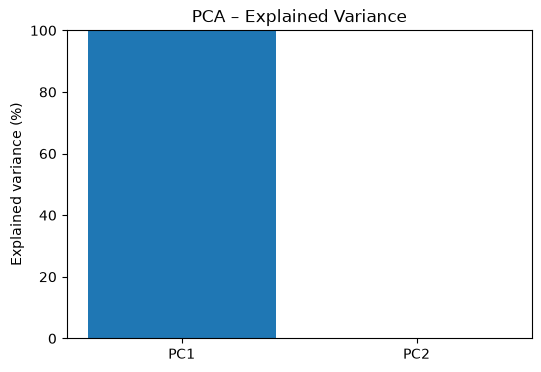

In [12]:
# Plot explained variance
plt.figure(figsize=(6, 4))
plt.bar(["PC1", "PC2"], explained_variance_ratio)
plt.ylabel("Explained variance (%)")
plt.title("PCA – Explained Variance")
plt.ylim(0, 100)
plt.show()

In [13]:
# Step 5: Apply PCA and reduce two features to one component
pca = PCA(n_components=1)
principal_components = pca.fit_transform(pca_standardized)

reduced_df = pd.DataFrame(
    principal_components,
    columns=["PC1"],
    index=pca_data.index
)

print("Reduced Dataset (one principal component):")
display(reduced_df.round(6))

Reduced Dataset (one principal component):


,PC1
S1,-1.897367
S2,-0.632456
S3,0.632456
S4,1.897367


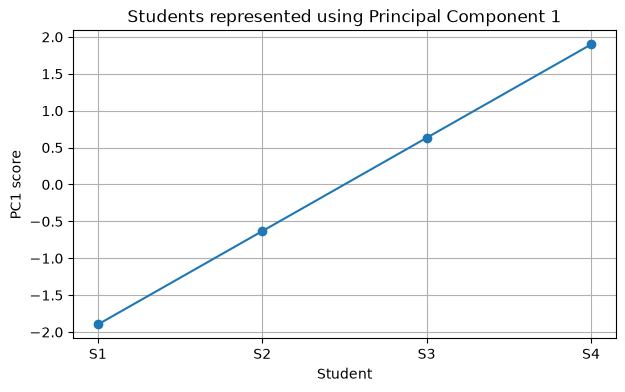

In [14]:
# Optional: Compare the original two-dimensional data with the PC1 scores
plt.figure(figsize=(7, 4))
plt.plot(pca_data.index, reduced_df["PC1"], marker="o")
plt.xlabel("Student")
plt.ylabel("PC1 score")
plt.title("Students represented using Principal Component 1")
plt.grid(True)
plt.show()